# Supplementary Figure S5e. Heritability of cis-MaxPIP versus union trans-MaxPIP annotations

Per brain-related trait, LDSC heritability attributed to the fine-mapped cis-eQTL MaxPIP annotation (x, annotation `cis_eQTL`) versus the union trans-MaxPIP annotation combining TransMap-eGene and TransMap-local (y, annotation `Trans_ALL_Remove`), from `ldsc_reg_res_h2/all_traits_all_annotations_h2_summary_with_status.tsv` (rows with status OK and SE > 0). Crosses are h2 ± 1.96 × SE (95% CI). Points are coloured by which estimate is larger (no test); the dashed line is y = x. Labelled traits follow the source rule: the two traits with the largest trans h2 among trans > cis, the trait with the largest cis − trans difference, and Alzheimer's disease. Source: `Manu_Figures/Figure2.ipynb` cell 71. The trait list in that cell names 30 traits, but the cell strips ".parquet" from trait IDs before matching, so Epigenetic Aging (mvAge) and Telomere Length (IDs ending in ".tsv.parquet") silently drop out although both have h2 estimates; Alzheimer's disease is kept by a separate pattern match. The remaining 28 traits match the caption's count, and the same filter is reproduced here.

Input: `data/Figure_S5e_cis_trans_h2.rds`.

In [1]:
library(ggplot2)
library(ggrepel)
d <- readRDS("data/Figure_S5e_cis_trans_h2.rds")
d

trait,trait_label,cis_h2,cis_se,trans_h2,trans_se,direction
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
accumbens,Nucleus Accumbens Volume,0.0722,0.0090,0.1286,0.0206,trans > cis
AD_Bellenguez_buildGRCh38_munged,Alzheimer's Disease,0.0266,0.0024,0.0284,0.0031,trans > cis
ALS-Rheenen-2021.GCST90027164_buildGRCh37,Amyotrophic Lateral Sclerosis,0.0384,0.0055,0.0370,0.0071,cis > trans
amygdala,Amygdala Volume,0.0369,0.0070,0.0490,0.0165,trans > cis
brainstem,Brainstem Volume,0.1660,0.0159,0.2015,0.0270,trans > cis
caudate,Caudate Volume,0.1088,0.0113,0.1602,0.0229,trans > cis
image_AD1,DNE-AD1 (Temporal Atrophy),0.1066,0.0119,0.1640,0.0217,trans > cis
image_AD2,DNE-AD2 (Subcortical Pattern),0.1214,0.0115,0.1231,0.0218,trans > cis
image_Aging1,DNE-Aging1,0.1566,0.0136,0.2102,0.0219,trans > cis


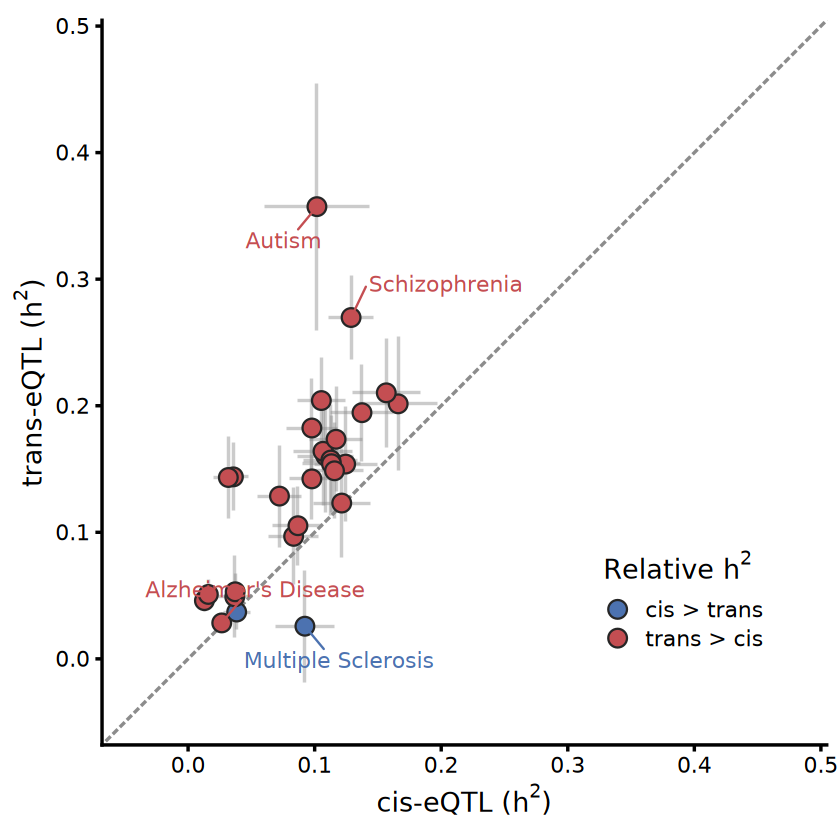

In [2]:
lims <- range(c(d$cis_h2 - 1.96 * d$cis_se, d$cis_h2 + 1.96 * d$cis_se,
                d$trans_h2 - 1.96 * d$trans_se, d$trans_h2 + 1.96 * d$trans_se))
lims <- lims + c(-1, 1) * 0.05 * diff(lims)
lab <- rbind(head(d[d$direction == "trans > cis", ][order(-d$trans_h2[d$direction == "trans > cis"]), ], 2),
             head(d[d$direction == "cis > trans", ][order((d$trans_h2 - d$cis_h2)[d$direction == "cis > trans"]), ], 1),
             d[d$trait_label == "Alzheimer's Disease", ])
lab <- lab[!duplicated(lab$trait), ]
cols <- c("trans > cis" = "#C44E52", "cis > trans" = "#4C72B0", "similar" = "grey70")
p <- ggplot(d, aes(x = cis_h2, y = trans_h2)) +
  geom_abline(slope = 1, intercept = 0, linetype = "longdash", colour = "grey55") +
  geom_segment(aes(x = cis_h2 - 1.96 * cis_se, xend = cis_h2 + 1.96 * cis_se, yend = trans_h2), colour = "grey55", alpha = 0.45) +
  geom_segment(aes(xend = cis_h2, y = trans_h2 - 1.96 * trans_se, yend = trans_h2 + 1.96 * trans_se), colour = "grey55", alpha = 0.45) +
  geom_point(aes(fill = direction), shape = 21, size = 4.5, colour = "grey15") +
  geom_text_repel(data = lab, aes(label = trait_label, colour = direction), size = 4.5, box.padding = 1,
                  min.segment.length = 0, show.legend = FALSE, seed = 1) +
  scale_fill_manual(values = cols, name = expression("Relative " * h^2)) +
  scale_colour_manual(values = cols, guide = "none") +
  coord_equal(xlim = lims, ylim = lims) +
  labs(x = expression("cis-eQTL (" * h^2 * ")"), y = expression("trans-eQTL (" * h^2 * ")")) +
  theme_classic(base_size = 16) + theme(legend.position = c(0.8, 0.2))
options(repr.plot.width = 7, repr.plot.height = 7)
p